# Array 51771061 — does KB (`no_mlp L=16 d128`) replicate on fresh seeds?

Stage K (finding 54, array `51668331`) measured the two narrow rungs of the
`L=16` width ladder at three seeds each:

| rung | architecture | trainable | `rho_50` | cross | escapes |
|---|---|---|---|---|---|
| KA | attention-only `L=16 d160` | 1,759,738 | 0.757 | 3/3 | 3/3 |
| KB | attention-only `L=16 d128` | 1,145,658 | 0.766 | 3/3 | 2/3 |

The standing minimum stayed `no_mlp L=16 d192` — J2, 2,504,890 trainable at
`rho_50` 0.580, finding 53 — because the replacement rule (H3 = I3 = J3 = K2)
needs **3 of 3 crossing AND a median at or below the free line 0.740**, and KB's
0.766 misses by `+0.026` = `+0.18` s\*. **A narrow miss on three seeds is
exactly the shape of result that three more seeds can settle**, in either
direction, which is what makes this stage worth 3 cells at 1.1M parameters.

**What stage N changes: the seed triple, and nothing else.** Seeds 3/4/5 of the
identical KB cell — same `arch_mode`, `num_layers`, `d_model`,
`dim_feedforward`, `nhead`, warmup, the same 240k × 50-epoch budget, the same
`--shuffle-adj --fall` leak-free ensemble, the same 14-point grid to a floor of
0.33 at 400 instances per bin. Section 3 checks that claim field by field
against all six `config.json` files rather than asserting it.

**The registered hypotheses, from `scripts/stagen_score.py` (`f419fec`),
committed by a registration job that the training array depended on with
`--dependency=afterok`, so no cell could start ahead of it:**

* **N0 — replication of the LEVEL.** The fresh triple's median `rho_50` lands in
  `[0.618, 0.914]` (stage K's 0.766 ± one s\* = 0.1484). Below means 0.766 was
  pessimistic and the pooled median may go free; above means the bottom of the
  ladder is worse than finding 54 reports.
* **N1 — replication of the CROSSING.** All 3 fresh seeds return a measured
  `rho_50` on a grid whose floor is 0.33. A censor is this stage's result, not a
  missing number.
* **N2 — the POOLED call, pooling rule fixed at registration.** Pool K's 0/1/2
  with N's 3/4/5 and apply the replacement rule to all six: KB takes the
  standing minimum only if **6 of 6 cross AND the six-seed median `rho_50` ≤
  0.740**. Applying stage K's 3-of-3 rule to a six-seed pool is the slip the
  registration was written to stop. Registered prediction: KB stays past the
  free line. Registered upside: if the six-seed median is free, KB at 1,145,658
  replaces the minimum — a 2.19× reduction.
* **N3 — the PLATEAU.** Pooled escapes below train NLL 1.64 are ≥ 4 of 6. Fewer
  means d128 at `L=16` is optimization-limited rather than capacity-limited, and
  the ~2M floor becomes a floor on what this *recipe trains*, not on what the
  task needs.
* **N4 — ACCURACY FIRST.** Validation token accuracy is read before `rho_50`
  because it never censors; all six KB cells sit on `acc_vs_solve.py`'s N=48
  fitted curve within the 0.0423 leave-one-out bar. A cell falling OFF it is the
  interesting one and is the headline over N2.

**Reading order, also registered: N4a → N1 → N0 → N2 → N3.** N1 or N3 falsified
outranks N2, because a level computed from a censoring rung is a bound, and an
optimization-limited rung changes what to try next — a better schedule, not a
bigger model.

**The bars are N=48 bars, reused and not refrozen:** s\* = 0.1484 (`rho_50`) /
0.2918 (`mean_solve`), free line 0.740, plateau 1.64, LOO bar 0.0423. Stage M's
N=96 bars (0.117 / 0.1586 / 0.0079) are a different size and appear nowhere
below; finding 55 is the standing reason the two sizes are never differenced.

In [1]:
import json, os, subprocess, sys
sys.path.insert(0, "/home/users/hshunt/spin_gnn")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

REPO = "/home/users/hshunt/spin_gnn"
BOOT = 2000            # the programme's scoring default; CIs here match the scorers'
from statistics import median

from scripts.minarch_analysis import SCAN_DIRS, SCAN_E, SCAN_G, SCAN_H, SCAN_I, SCAN_J
from scripts.stagec_score import (HUB, PLATEAU, S_MEAN, S_RHO50, escapes, rho_txt,
                                  rung, summarize)
from scripts.stagej_score import LOO_BAR, SUFFICIENCY_DIRS
from scripts.stagek_score import (E2, FREE, H1, H2, HUB_RHO50, HUB_TRAINABLE, I1, J1,
                                  KA, PREDICTED_TRAINABLE, SCAN_K, STANDING)
from scripts.stagen_score import (J2, KB, KB_K_ESCAPES, KB_K_RHO50, KB_TRAINABLE,
                                  K_SEEDS, N_SEEDS, PRED_HI, PRED_LO, SCAN_N,
                                  STANDING_RHO50, STANDING_TRAINABLE)
from scripts.stagen_score import acc_of as seed_acc
from notebooks.make_stagek_deck import FULL_L12
from notebooks.make_stagen_deck import (collect, escaped, kb_residuals, qualifies6,
                                        rows_for, seedmap, split_by_escape,
                                        verdict_n0, verdict_n1, verdict_n3)

# SCAN_N and SCAN_K are read here and HAVE to be -- they are the subject. Both
# stay out of SCAN_DIRS, and so out of the pooled s*, because their rungs would
# otherwise enter the yardstick stages A-F were already scored against. s* is
# quoted frozen below and never recomputed.
assert SCAN_N not in SCAN_DIRS and SCAN_K not in SCAN_DIRS, "a replicate leaked into the yardstick"
DIRS = [d for d in SCAN_DIRS + [SCAN_E, SCAN_G, SCAN_H, SCAN_I, SCAN_J, SCAN_K, SCAN_N]
        if os.path.isdir(d)]

COMMIT = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=REPO,
                        capture_output=True, text=True).stdout.strip()
print("git commit        ", COMMIT)
print("branch            ", subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"],
                                           cwd=REPO, capture_output=True,
                                           text=True).stdout.strip())
print("scorer registered ", "f419fec, by the job the training array depended on")
print("deck registered   ", "a18169f, before any fresh cell had an eval on disk")
print("training array    ", "51771061 (seeds 3/4/5), scorer 51771069")
print("bootstrap draws   ", BOOT)
print("seeds             ", f"stage K {K_SEEDS}, stage N {N_SEEDS} -- pooled to six")
print("frozen yardstick  ", f"s* = {S_RHO50} in rho_50, {S_MEAN} in mean_solve")
print("plateau           ", f"train NLL {PLATEAU} (finding 44, an N=48 number)")
print("free line         ", f"rho_50 <= {FREE:.3f} (hub {HUB_RHO50} + s*)")
print("N0 bracket        ", f"[{PRED_LO:.3f}, {PRED_HI:.3f}] around stage K's {KB_K_RHO50:.3f}")
print("N2 rule           ", f"6 of 6 cross AND six-seed median <= {FREE:.3f}")
print("N3 bar            ", f">= 4 of 6 escape {PLATEAU} (stage K: {KB_K_ESCAPES} of 3)")
print("sufficiency bar   ", f"leave-one-out RMS {LOO_BAR}")
print("scan dirs         ", len(DIRS), "dirs; the subject is", os.path.basename(SCAN_N))

git commit         43e013b
branch             sudoku-dd
scorer registered  f419fec, by the job the training array depended on
deck registered    a18169f, before any fresh cell had an eval on disk
training array     51771061 (seeds 3/4/5), scorer 51771069
bootstrap draws    2000
seeds              stage K (0, 1, 2), stage N (3, 4, 5) -- pooled to six
frozen yardstick   s* = 0.1484 in rho_50, 0.2918 in mean_solve
plateau            train NLL 1.64 (finding 44, an N=48 number)
free line          rho_50 <= 0.740 (hub 0.592 + s*)
N0 bracket         [0.618, 0.914] around stage K's 0.766
N2 rule            6 of 6 cross AND six-seed median <= 0.740
N3 bar             >= 4 of 6 escape 1.64 (stage K: 2 of 3)
sufficiency bar    leave-one-out RMS 0.0423
scan dirs          11 dirs; the subject is sudoku_n48_kbrep_N_2026-11-10


## 2. The headline, selected by the branch the data fell in

`qualifies6` transcribes N2's registered pooling rule — 6 of 6 crossing AND a
six-seed median at or below 0.740 — and `verdict_n0` / `verdict_n1` /
`verdict_n3` are the same functions that pick the deck's page titles, so the
slides and this page cannot disagree about which branch happened. The cell
selects a branch; it does not compose a sentence.

In [2]:
cells, raw = collect(DIRS, BOOT)
cells = seedmap(cells)

pooled = rows_for(cells, KB)
fresh = rows_for(cells, KB, N_SEEDS)
old = rows_for(cells, KB, K_SEEDS)
j2 = rows_for(cells, J2)
ka = rows_for(cells, KA)

s = pooled["s"]
print(f"{len(cells)} cells on disk | KB {s['n']}/6 seeds "
      f"({old['s']['n']} from K, {fresh['s']['n']} from N)" + chr(10))

print("the registered reading order, one line each:")
print(f"  N4a accuracy   K median {median(a for _, a in seed_acc(old['ms'])):.4f}   "
      f"N median {median(a for _, a in seed_acc(fresh['ms'])):.4f}")
print(f"  N1  crossing   {fresh['s']['n_cross']}/{fresh['s']['n']} fresh seeds measured "
      f"-> {verdict_n1(fresh).upper()}")
print(f"  N0  level      fresh median {rho_txt(fresh['s'])} in "
      f"[{PRED_LO:.3f}, {PRED_HI:.3f}]? -> {verdict_n0(fresh).upper()}")
print(f"  N2  pooled     {rho_txt(s)} over {s['n']} seeds, {s['n_cross']}/{s['n']} cross "
      f"-> {'TAKES THE MINIMUM' if qualifies6(s) else 'MINIMUM HOLDS'}")
print(f"  N3  plateau    {pooled['esc']}/{s['n']} escaped {PLATEAU} "
      f"-> {verdict_n3(pooled).upper()}")

print()
print(f"  {'rung':<34}{'rho_50':>10}{'mean_solve':>12}{'cross':>8}{'esc':>6}{'trainable':>12}")
print("  " + "-" * 82)
for nm, r in (("KB  stage K seeds 0/1/2", old), ("KB  stage N seeds 3/4/5", fresh),
              ("KB  POOLED, six seeds", pooled)):
    t = r["s"]
    print(f"  {nm:<34}{rho_txt(t):>10}{t['mean_solve']:>12.4f}"
          f"{t['n_cross']:>5}/{t['n']}{r['esc']:>4}/{t['n']}{t['trainable']:>12,}")

print()
if qualifies6(s):
    print(f"  N2: KB SATISFIES the pooled rule. The minimum MOVES to "
          f"attention-only L=16 d128,")
    print(f"      {KB_TRAINABLE:,} at {s['rho50']:.3f} -- "
          f"{STANDING_TRAINABLE / KB_TRAINABLE:.2f}x below {STANDING[0]}.")
    print(f"      This is an N=48 claim: finding 55 says the N=48 minimum does not "
          f"transfer to N=96.")
else:
    why = ("not all six crossed" if s["n_cross"] < s["n"] else
           "the pooled median censors" if not s["rho50_readable"] else
           f"the median is {(s['rho50'] - FREE) / S_RHO50:+.2f} s* past {FREE:.3f}")
    print(f"  N2: KB does NOT take the minimum ({why}).")
    print(f"      The standing minimum is UNCHANGED at {STANDING[1]}, "
          f"{STANDING_TRAINABLE:,} at {STANDING_RHO50:.3f}.")
    print(f"      That is this stage's result and it is a NEGATIVE one: six seeds of "
          f"the smallest")
    print(f"      crossing rung still do not make it free.")

108 cells on disk | KB 6/6 seeds (3 from K, 3 from N)

the registered reading order, one line each:
  N4a accuracy   K median 0.4817   N median 0.4829
  N1  crossing   3/3 fresh seeds measured -> HELD
  N0  level      fresh median 0.759 in [0.618, 0.914]? -> HELD
  N2  pooled     0.761 over 6 seeds, 6/6 cross -> MINIMUM HOLDS
  N3  plateau    5/6 escaped 1.64 -> HELD

  rung                                  rho_50  mean_solve   cross   esc   trainable
  ----------------------------------------------------------------------------------
  KB  stage K seeds 0/1/2                0.766      0.3168    3/3   2/3   1,145,658
  KB  stage N seeds 3/4/5                0.759      0.3096    3/3   3/3   1,145,658
  KB  POOLED, six seeds                  0.761      0.3118    6/6   5/6   1,145,658

  N2: KB does NOT take the minimum (the median is +0.14 s* past 0.740).
      The standing minimum is UNCHANGED at attention-only L=16 d192, 2,504,890 at 0.580.
      That is this stage's result and it is a

## 3. Provenance: the seed is the only field that moves

Stage K's provenance section had one knob, `d_model`. Stage N has a narrower
one still: **`seed`**. Every other field of the six `config.json` files is
identical, and the cell below prints the diff per cell rather than asserting
it — including against J2, the standing minimum this rung is being compared
with, where the expected difference is `d_model` alone.

This is what makes the two triples poolable *mechanically* as well as
statistically: fresh seeds cannot collide with K's 0/1/2 in the pooled cell key,
so `rung(cells, KB)` returns six rows and not three overwritten ones. The
`trainable` check against the registered formula — `4*d^2 + 8*d` per layer plus
`630*d + 58` fixed, asserted by the sbatch before training — is what would have
caught a cell that built a different model under the same name.

In [3]:
FIELDS = ("num_layers", "d_model", "dim_feedforward", "nhead", "arch_mode", "epochs",
          "lr", "lr_schedule", "batch_size", "n_train_instances", "warmup_epochs",
          "shuffle_adj", "fall", "n_nodes", "degree", "n_colors")
cfgs = {m["seed"]: json.load(open(os.path.join(m["path"], "config.json")))
        for m in pooled["ms"]}
base = cfgs[min(cfgs)]
print(f"{'cell':<22}" + "".join(f"{f.replace('_', ' ')[:11]:>13}" for f in FIELDS[:5]))
print("-" * 87)
for seed in sorted(cfgs):
    stage = "K" if seed in K_SEEDS else "N  FRESH"
    print(f"{'KB seed ' + str(seed) + '  [' + stage + ']':<22}"
          + "".join(f"{str(cfgs[seed].get(f)):>13}" for f in FIELDS[:5]))

print()
print("THE ONE FIELD THAT MOVES: seed. Everything else, per cell:")
# solve_metrics, baseline_accuracy and n_trainable_params are written back into
# config.json by the runner -- outputs of the cell, not inputs.
OUTPUTS = ("out_dir", "run_name", "seed", "solve_metrics", "baseline_accuracy",
           "n_trainable_params")
for seed in sorted(cfgs):
    a = cfgs[seed]
    diff = sorted(k for k in set(a) | set(base) if a.get(k) != base.get(k)
                  and k not in OUTPUTS)
    print(f"  seed {seed}: fields differing besides seed: {diff or 'NONE'}")
print()
print("held constant across all 6 cells:",
      "  ".join(f"{f}={base.get(f)}" for f in FIELDS[5:]))

print()
print("AND against J2, the standing minimum KB is measured against:")
j2cfg = json.load(open(os.path.join(j2["ms"][0]["path"], "config.json")))
jdiff = sorted(k for k in set(j2cfg) | set(base) if j2cfg.get(k) != base.get(k)
               and k not in OUTPUTS)
print(f"  J2 vs KB: fields differing besides seed: {jdiff or 'NONE'}"
      f"   (d_model {j2cfg['d_model']} vs {base['d_model']})")

print()
print("THE BUDGET -- registered formula vs what the models actually built")
L, d = KB[0], KB[3]
want = PREDICTED_TRAINABLE["KB"]
assert want == L * (4 * d * d + 8 * d) + 630 * d + 58, "formula disagrees with registration"
assert want == KB_TRAINABLE, "the registered KB budget moved"
for seed in sorted(cfgs):
    got = [m for m in pooled["ms"] if m["seed"] == seed][0]["n_trainable"]
    print(f"  KB seed {seed}   predicted {want:>10,}   observed {got:>10,}   "
          f"{'ok' if want == got else 'MISMATCH'}")

cell                     num layers      d model  dim feedfor        nhead    arch mode
---------------------------------------------------------------------------------------
KB seed 0  [K]                   16          128         1024            4       no_mlp
KB seed 1  [K]                   16          128         1024            4       no_mlp
KB seed 2  [K]                   16          128         1024            4       no_mlp
KB seed 3  [N  FRESH]            16          128         1024            4       no_mlp
KB seed 4  [N  FRESH]            16          128         1024            4       no_mlp
KB seed 5  [N  FRESH]            16          128         1024            4       no_mlp

THE ONE FIELD THAT MOVES: seed. Everything else, per cell:
  seed 0: fields differing besides seed: NONE
  seed 1: fields differing besides seed: NONE
  seed 2: fields differing besides seed: NONE
  seed 3: fields differing besides seed: NONE
  seed 4: fields differing besides seed: NONE
  seed

## 4. The metrics table

`rho_50` is the realized hint density at which the solve rate crosses 0.5 on a
14-point × 400-instance leak-free grid (`--shuffle-adj --fall`), **lower is
better**, reported CENSORED when no bin crosses. `mean_solve` is the unweighted
mean over the 14 bins and never censors. `spread` is the seed-to-seed range in
`mean_solve` against the frozen bar s\* = 0.2918 on that metric. `esc` counts
seeds whose final train NLL fell below the **1.64** plateau (finding 44) — the
gate that separates "this architecture cannot do the task" from "this cell did
not train".

The second block is the one the rest of this notebook turns on. N3's escape
criterion was registered as a *plateau* call, but it also partitions the six
seeds, and the partition is not subtle: conditioning on it is not the same as
dropping an inconvenient point, and the two spreads differ by an order of
magnitude. Whether that partition is coherent — one seed low on *every* metric,
not just on `rho_50` — is checked per metric rather than assumed.

In [4]:
print(f"  {'rung':<34}{'rho_50':>10}{'mean_solve':>12}{'spread':>9}{'cross':>8}"
      f"{'esc':>6}{'tok acc':>10}{'train NLL':>11}{'trainable':>12}")
print("  " + "-" * 112)
for nm, r in (("KB  L=16 d128, K seeds 0/1/2", old),
              ("KB  L=16 d128, N seeds 3/4/5", fresh),
              ("KB  L=16 d128, POOLED", pooled),
              ("KA  L=16 d160, 3 seeds", ka),
              ("J2  L=16 d192, standing min", j2)):
    if r is None:
        continue
    t, nll = r["s"], sorted(escapes(r["ms"])[1])
    print(f"  {nm:<34}{rho_txt(t):>10}{t['mean_solve']:>12.4f}{t['spread_mean']:>9.4f}"
          f"{t['n_cross']:>5}/{t['n']}{r['esc']:>4}/{t['n']}{r['acc']:>10.4f}"
          f"{nll[len(nll) // 2]:>11.4f}{t['trainable']:>12,}")

print()
print("  per-seed, all six KB cells, in seed order")
print(f"    {'seed':<6}{'stage':<8}{'rho_50':>9}{'mean_solve':>12}{'tok acc':>10}"
      f"{'train NLL':>11}{'escaped':>10}")
print("    " + "-" * 66)
accs = dict(seed_acc(pooled["ms"]))
for m in pooled["ms"]:
    nll = sorted(escapes([m])[1])[0]
    print(f"    s{m['seed']:<5}{'K' if m['seed'] in K_SEEDS else 'N':<8}"
          + (f"{m['rho50']:>9.3f}" if m["flag"] == "ok" else f"{'CENSORED':>9}")
          + f"{m['mean_solve']:>12.4f}{accs[m['seed']]:>10.4f}{nll:>11.4f}"
          + f"{('yes' if escaped(m) else 'NO'):>10}")

print()
esc_r, stuck_r = split_by_escape(pooled["ms"])
readable = [m["rho50"] for m in pooled["ms"] if m["flag"] == "ok"]
print(f"  N3's criterion partitions the six: {len(esc_r)} escaped, {len(stuck_r)} did not.")
print(f"    raw six-seed rho_50 spread        {max(readable) - min(readable):.3f}"
      f"   = {(max(readable) - min(readable)) / S_RHO50:.2f} s*")
if len(esc_r) > 1:
    print(f"    spread among the escaping seeds   {max(esc_r) - min(esc_r):.3f}"
          f"   = {(max(esc_r) - min(esc_r)) / S_RHO50:.2f} s*")
if stuck_r:
    print(f"    the seed(s) that never escaped    "
          + ", ".join(f"{v:.3f}" for v in sorted(stuck_r)))
    print(f"    ratio of the two spreads          "
          f"{(max(readable) - min(readable)) / (max(esc_r) - min(esc_r)):.1f}x")

print()
print("  IS THE PARTITION COHERENT? the stuck seed's rank on each metric, 1 = worst")
print("  (if it is last on every one, it is a training failure and not a rho_50 outlier)")
stuck_seeds = [m["seed"] for m in pooled["ms"] if m["flag"] == "ok" and not escaped(m)]
for seed in stuck_seeds:
    for label, vals, worst_is_high in (
            ("rho_50    ", {m["seed"]: m["rho50"] for m in pooled["ms"] if m["flag"] == "ok"}, True),
            ("mean_solve", {m["seed"]: m["mean_solve"] for m in pooled["ms"]}, False),
            ("tok acc   ", accs, False),
            ("train NLL ", {m["seed"]: sorted(escapes([m])[1])[0] for m in pooled["ms"]}, True)):
        order = sorted(vals, key=lambda k: -vals[k] if worst_is_high else vals[k])
        print(f"    s{seed}  {label}  rank {order.index(seed) + 1} of {len(order)}"
              f"   value {vals[seed]:.4f}")

  rung                                  rho_50  mean_solve   spread   cross   esc   tok acc  train NLL   trainable
  ----------------------------------------------------------------------------------------------------------------
  KB  L=16 d128, K seeds 0/1/2           0.766      0.3168   0.2252    3/3   2/3    0.4817     1.6155   1,145,658
  KB  L=16 d128, N seeds 3/4/5           0.759      0.3096   0.0045    3/3   3/3    0.4829     1.5997   1,145,658
  KB  L=16 d128, POOLED                  0.761      0.3118   0.2252    6/6   5/6    0.4829     1.6084   1,145,658
  KA  L=16 d160, 3 seeds                 0.757      0.3163   0.2136    3/3   3/3    0.4858     1.5550   1,759,738
  J2  L=16 d192, standing min            0.580      0.5527   0.2586    3/3   3/3    0.4940     1.5356   2,504,890

  per-seed, all six KB cells, in seed order
    seed  stage      rho_50  mean_solve   tok acc  train NLL   escaped
    ------------------------------------------------------------------
    s0    K  

## 5. The registered scorer, run verbatim

`scripts/stagen_score.py` was committed at `f419fec` by a registration job that
the training array depended on with `--dependency=afterok`, so not one of the
three fresh cells could start before the predictions were on disk. It is run
here as a subprocess so the words in this notebook and on the slides can be
checked against the words the scorer prints.

Two things in it are worth naming. **N2's pooling rule was fixed before any
fresh number existed** — 6 of 6 and a six-seed median — precisely because
choosing the rule afterwards is how a narrow miss becomes a hit. And **the
reading order is registered too**: N4a before N1 before N0 before N2, with N1
and N3 outranking N2, so a censored or untrained rung cannot be reported as a
level.

In [5]:
r = subprocess.run([sys.executable, "-m", "scripts.stagen_score"], cwd=REPO,
                   capture_output=True, text=True)
print("=" * 100)
print("$ python3 -m scripts.stagen_score")
print("=" * 100)
print(r.stdout)
if r.returncode != 0:
    print("STDERR:", r.stderr[-2000:])

$ python3 -m scripts.stagen_score
STAGE N -- does KB replicate? `no_mlp L=16 d128`, N=48, fresh seeds
  scanning: /scratch/users/hshunt/spin_gnn/sudoku_n48_kbrep_N_2026-11-10 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_K_2026-11-09
  bars (N=48, reused not refrozen): s* 0.1484 rho_50 / 0.2918 mean_solve, free 0.74, plateau 1.64, LOO 0.0423
  stage M's N=96 bars are a different size and appear nowhere below.

  on disk: 3 of stage K's 0/1/2, 3 of stage N's 3/4/5

=== N4a -- VALIDATION TOKEN ACCURACY, READ FIRST ==================
  The standing non-negotiable: accuracy never censors, so it is read
  before rho_50 and rho_50 only confirms it.
    seed 0  val token acc 0.4817   from stage K (0/1/2)
    seed 1  val token acc 0.4701   from stage K (0/1/2)
    seed 2  val token acc 0.4831   from stage K (0/1/2)
    seed 3  val token acc 0.4829   from stage N (3/4/5), FRESH
    seed 4  val token acc 0.4827   from stage N (3/4/5), FRESH
    seed 5  val token acc 0.4833   from stage N (3/

## 6. The figures, as they appear on the slides

Drawn by importing the deck module and handing it a sink that keeps the figure
open, so the notebook and the PDF cannot drift.

1. **The headline** — the pooled call against the free line, with the standing
   minimum beside it.
2. **The replication** — K's triple, N's triple and the pooled median against
   N0's registered bracket.
3. **The transition curves** — the solve-rate sweep each `rho_50` is read off,
   orange for K's seeds and blue for N's.
4. **The plateau** — training loss against the 1.64 line, which is where N3 is
   decided and where the spread in figure 3 gets its explanation.
5. **The accuracy residuals** — each seed's distance from the N=48
   accuracy-to-solve curve against the 0.0423 LOO bar, computed through
   `acc_vs_solve`'s own `pava`/`predict` over its own reference set.

The deck's two remaining pages are the mandatory content pages — the
tokenization and a worked reasoning trace — built by `deck_tokenization` with
`fall=True, shuffle_adj=True`, the instance keys these cells were trained and
scored on.

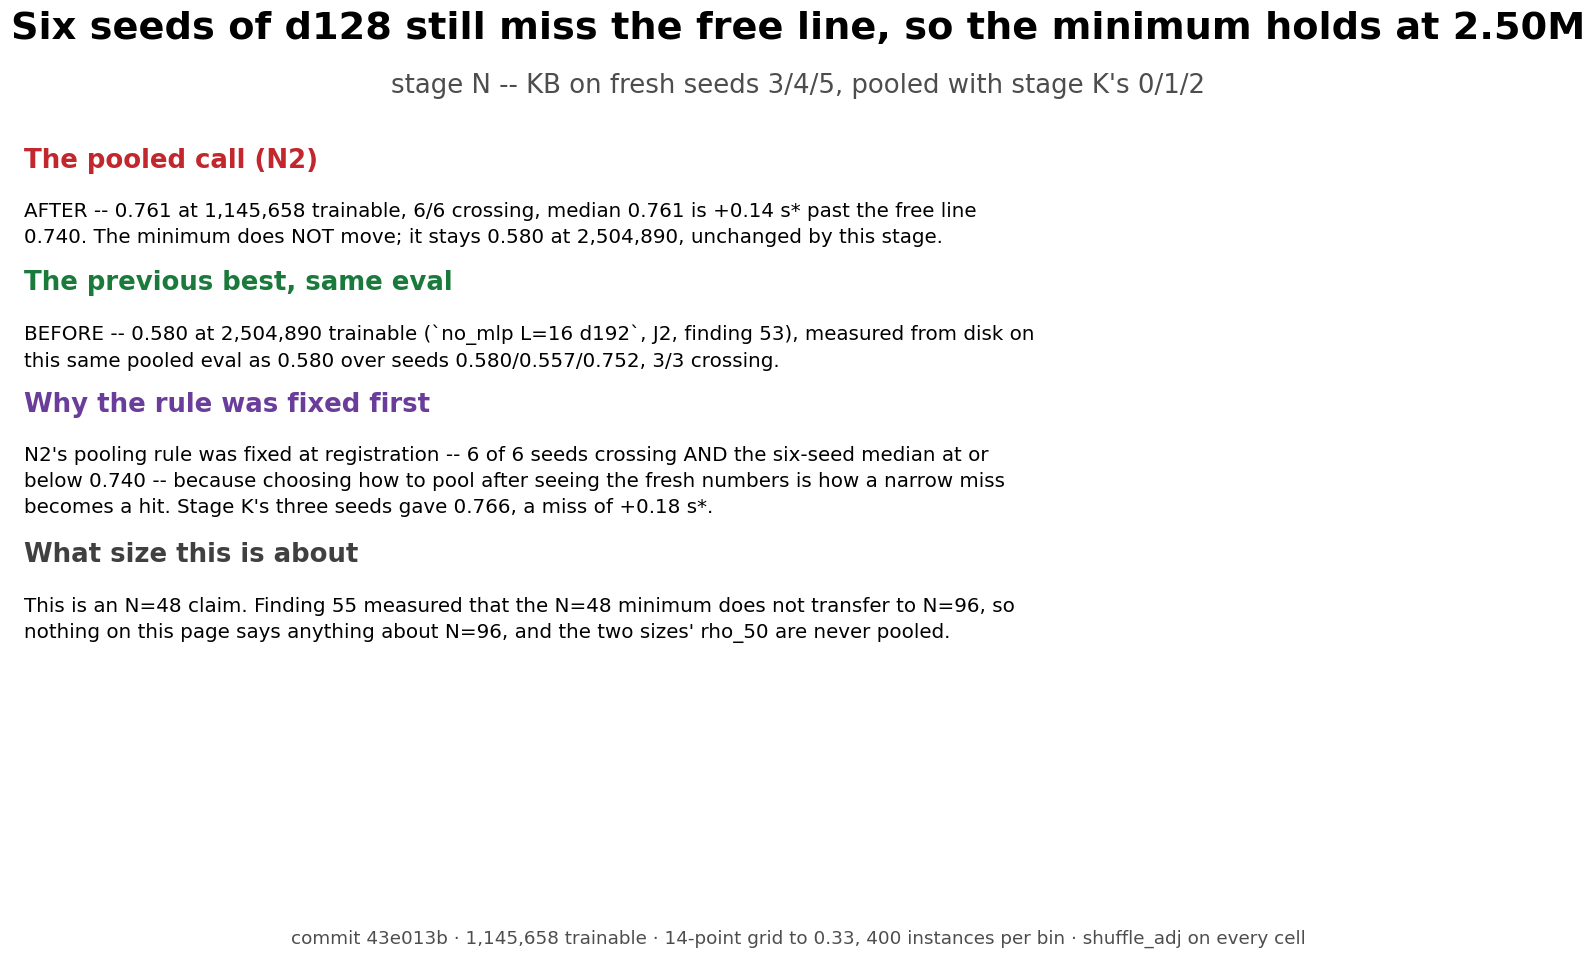

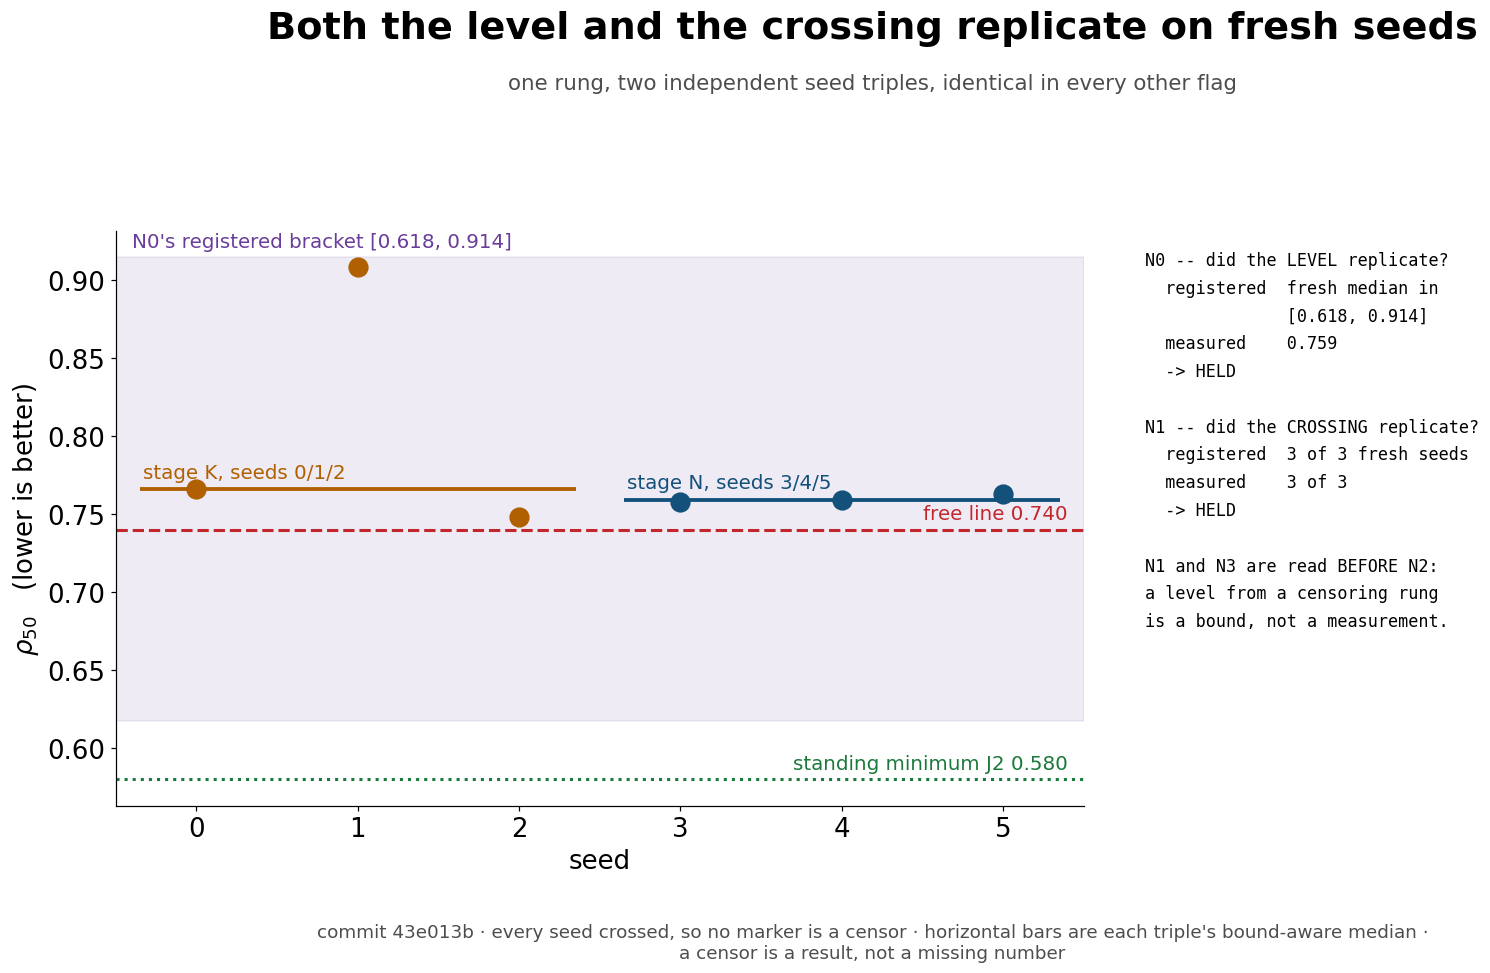

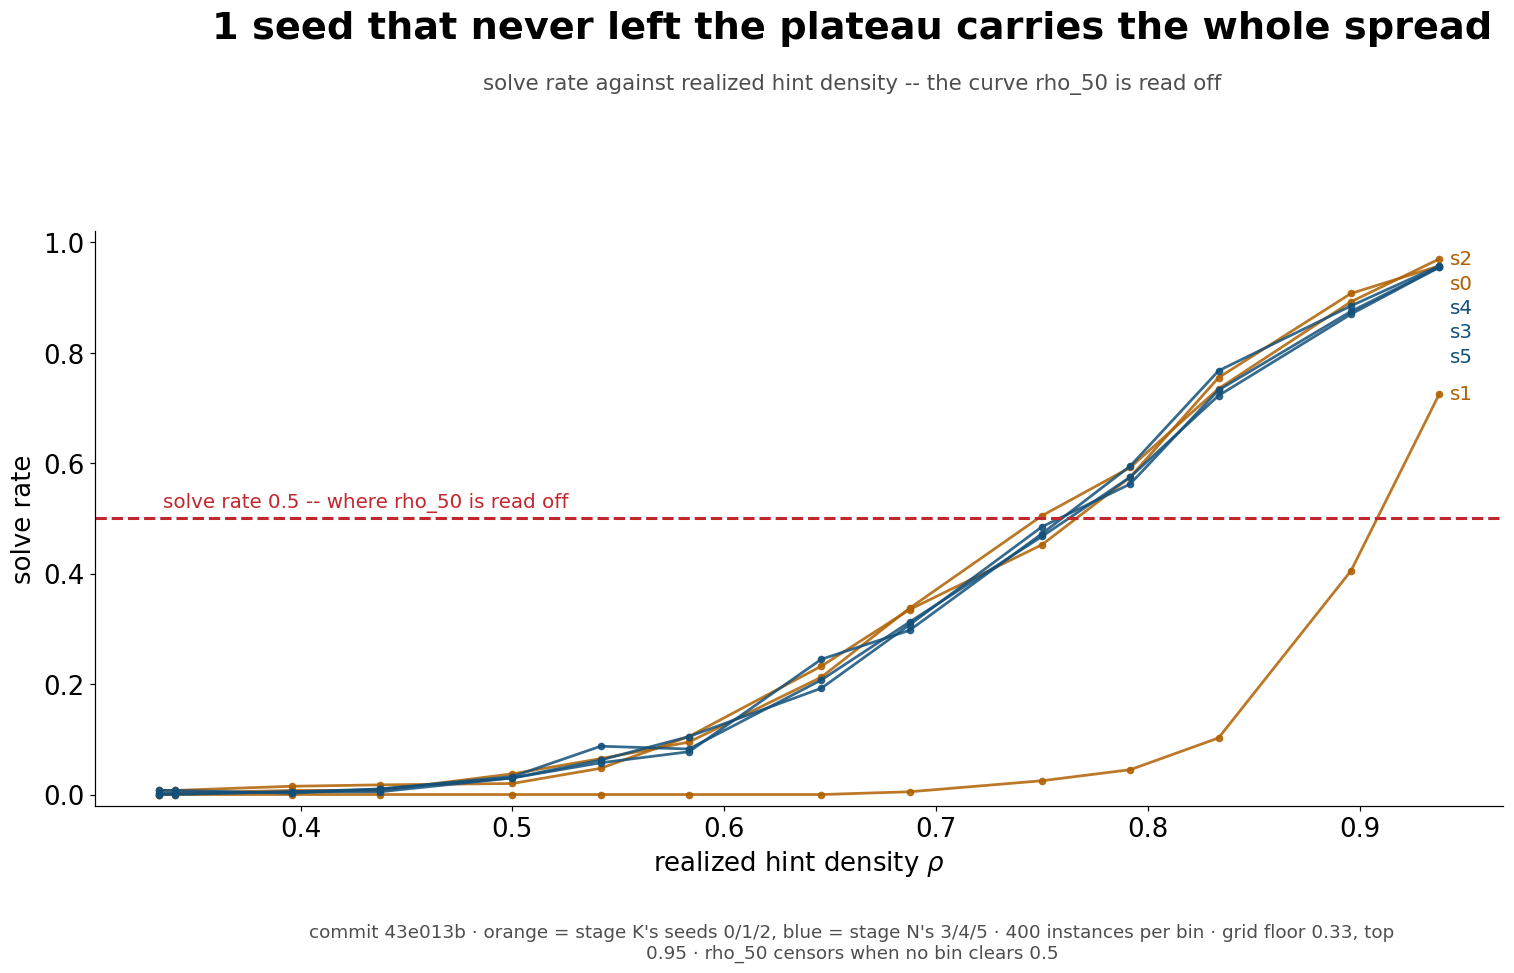

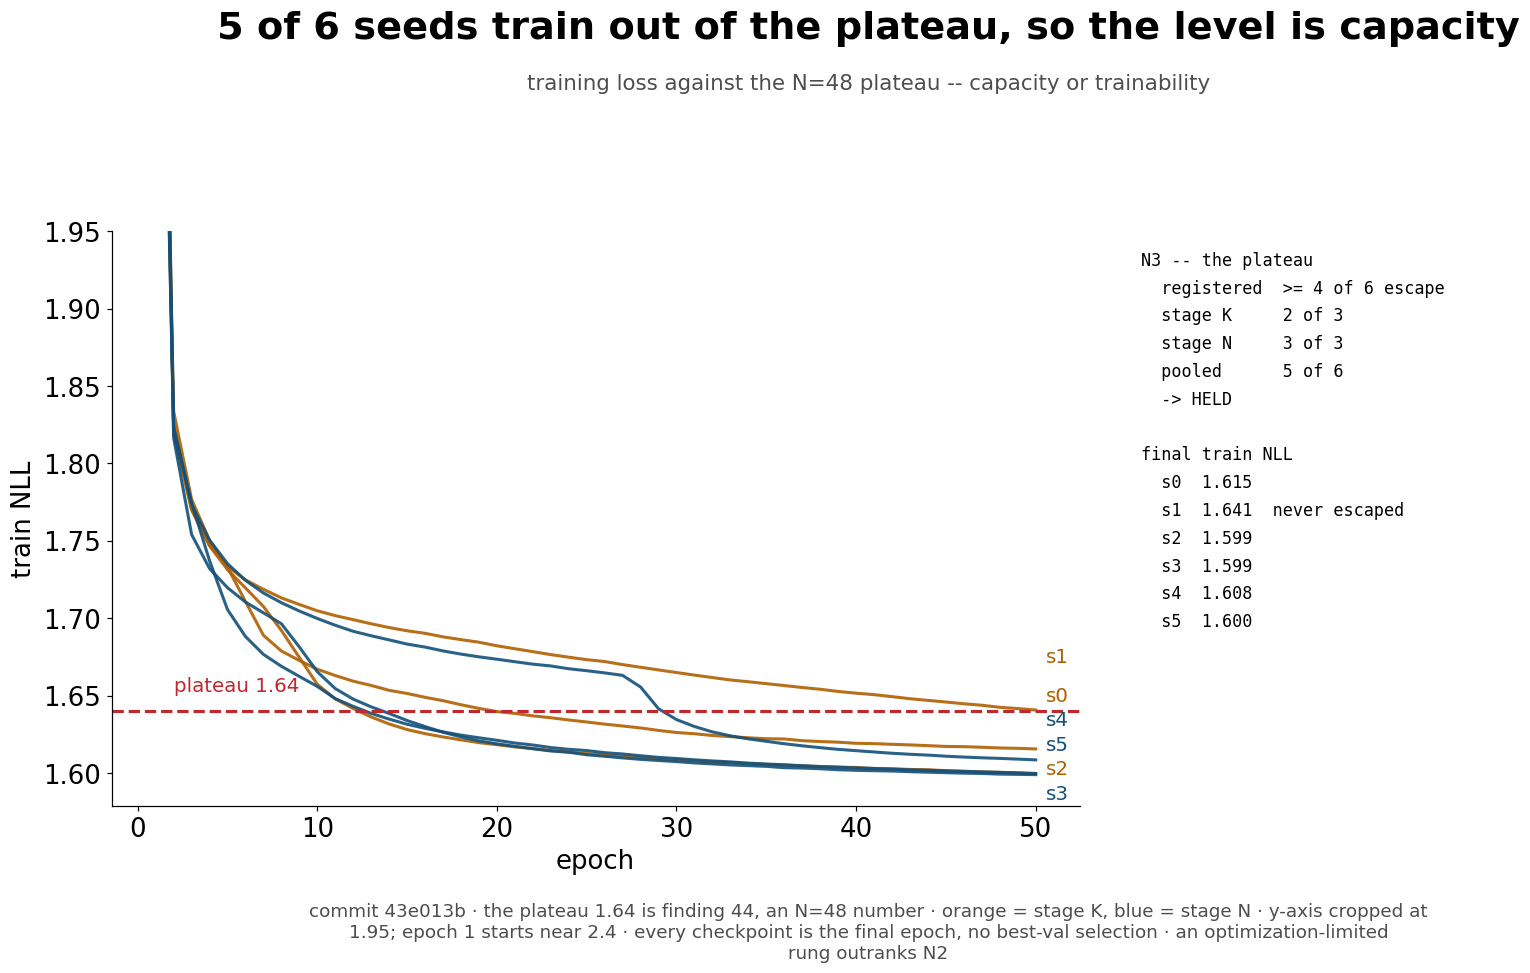

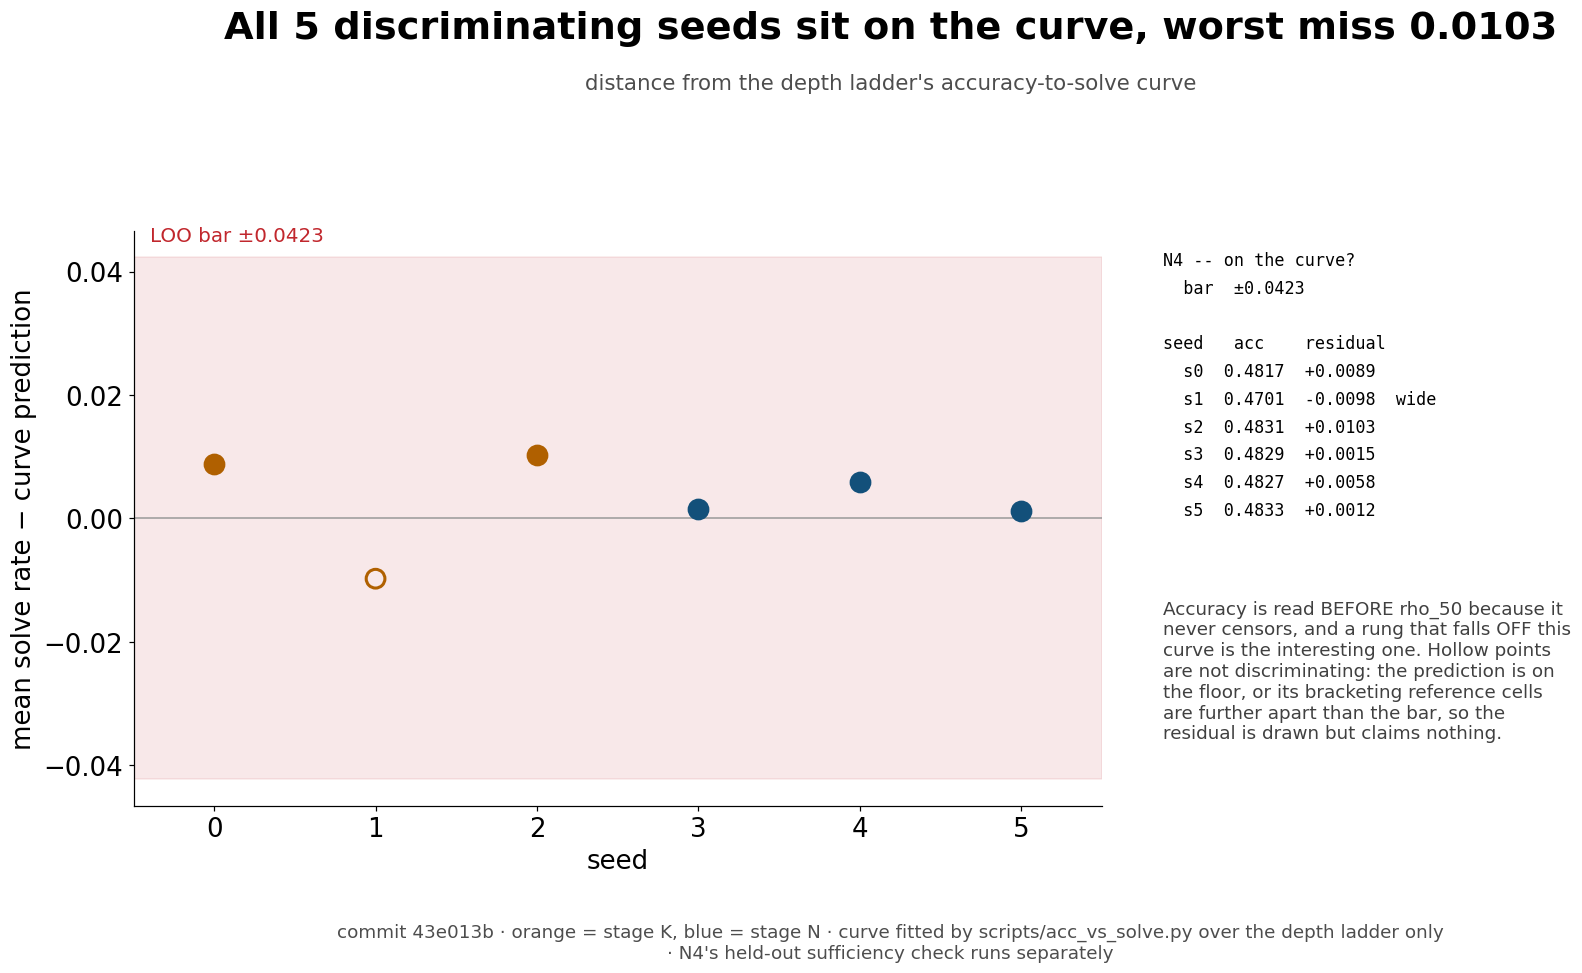

In [6]:
from notebooks.make_stagen_deck import (page_accuracy, page_headline, page_plateau,
                                        page_replication, page_transition)
from notebooks.deck_utils import set_style

set_style()


class Keep:
    # A PdfAndPng stand-in that keeps the figure open for the notebook.
    def savefig(self, fig):
        pass


o = Keep()
page_headline(o, pooled, fresh, old, j2, COMMIT)
page_replication(o, pooled, fresh, old, COMMIT)
page_transition(o, raw, pooled, COMMIT)
page_plateau(o, pooled, fresh, old, COMMIT)
page_accuracy(o, pooled, fresh, old, COMMIT)

## 7. N4b — does token accuracy still explain six seeds of one cell?

The programme's standing result is that a cell's mean solve rate is predicted by
its validation token accuracy alone, through a curve fitted on the **depth
ladder only** (full-width, 4-head, unmodified transformers at `L=1..12`). Every
stage since G has been a fresh test of it; stage N is the first at **six seeds
of a single cell**, which tests something the earlier stages could not. If a
seed fails in a way the curve does not see — low `rho_50` at ordinary token
accuracy — that is a deduction-specific failure mode, and N4 registered it as
the headline over N2.

The bar is the depth ladder's own leave-one-out residual, `LOO_BAR` = 0.0423.
Only **well-determined** cells count — ones bracketed by depth cells closer
together than the bar — and among those the **discriminating** ones are those
the curve sends above a solve rate of `FLOOR` = 0.10, where landing on the curve
is a real constraint rather than two numbers agreeing near zero. Both conditions
are required: a seed can fail to discriminate because its bracket is too wide
*or* because the prediction sits on the floor, and the second block below says
which.

In [7]:
r = subprocess.run([sys.executable, "-m", "scripts.acc_vs_solve", "--scan-dir"]
                   + list(SUFFICIENCY_DIRS) + [SCAN_K, SCAN_N],
                   cwd=REPO, capture_output=True, text=True)
tail = r.stdout.strip().split(chr(10))
keep = [l for l in tail if l.strip().startswith(">>>") or "Worst miss" in l
        or "DISCRIMINATING --" in l or "mean residual" in l
        or l.strip().startswith("RMS") or "DETERMINED --" in l]
print(chr(10).join(keep))
print()
print(f"  before stage N this was 22/22 well-determined rungs over 47 cells, worst 0.0222")

print()
print("  per-seed, recomputed in-process through acc_vs_solve's own pava/predict")
print(f"    {'seed':<6}{'tok acc':>10}{'predicted':>12}{'observed':>11}{'residual':>11}"
      f"{'counts?':>10}")
print("    " + "-" * 60)
res = kb_residuals(pooled)
for row in res:
    obs = row["pred"] + row["resid"]
    why = "yes" if not row["weak"] else row["why"]
    print(f"    s{row['seed']:<5}{row['acc']:>10.4f}{row['pred']:>12.4f}{obs:>11.4f}"
          f"{row['resid']:>+11.4f}{why:>10}")
strong = [row for row in res if not row["weak"]]
print()
print(f"  {len(strong)} of {len(res)} seeds are discriminating; worst miss among them "
      f"{max(abs(row['resid']) for row in strong):.4f} against the {LOO_BAR} bar")
print(f"  -> {'ALL ON THE CURVE' if all(abs(row['resid']) <= LOO_BAR for row in strong) else 'A SEED IS OFF THE CURVE -- this outranks N2'}")
print()
print("  This is a CORRELATIONAL result about this grid's range. It does not say the")
print("  architectures are the same model; it says no cut tried so far -- and no seed")
print("  of this cell -- has opened a second, deduction-specific way to fail.")

  RMS 0.0423, max |residual| 0.1232 over 21 depth cells
=== per rung, mean residual against the bar 0.0423 ===
  -- WELL-DETERMINED -- bracketed by depth cells closer together than the bar, so these rows carry the result
     L=12 h=4 no_mlp d192       n=2  mean residual +0.0076   EXPLAINED by token accuracy
     L=16 h=4 no_mlp d192       n=1  mean residual +0.0062   EXPLAINED by token accuracy
     L=6  h=4 no_mlp d384       n=2  mean residual +0.0061   EXPLAINED by token accuracy
     L=12 h=4 no_mlp d128       n=2  mean residual +0.0057   EXPLAINED by token accuracy
     L=16 h=4 no_mlp d128       n=5  mean residual +0.0055   EXPLAINED by token accuracy
     L=6  h=4 linear            n=3  mean residual +0.0036   EXPLAINED by token accuracy
     L=6  h=4 full ff256        n=1  mean residual +0.0036   EXPLAINED by token accuracy
     L=12 h=4 no_mlp            n=1  mean residual +0.0004   EXPLAINED by token accuracy
     L=6  h=4 no_mlp            n=2  mean residual +0.0003   EXPLAI

## 8. `rho_50` before and after, on the same eval

The eval is unchanged — the same 14-point × 400-instance leak-free grid,
`--shuffle-adj --fall` throughout, and the same frozen bar s\* = 0.1484 /
0.2918, fixed before any of these cells ran and not recomputed here. All six KB
cells ran 50 epochs on the same 240k pool as every rung they are compared
against, so these comparisons are within budget and legitimate.

**Which "before" is the right one.** The standing minimum moved on 2026-11-09,
from `no_mlp L=12 d256` (E2, 3,331,642 @ 0.605, finding 50) to `no_mlp L=16
d192` (J2, 2,504,890 @ 0.580, finding 53). Anything written before 11-09 that
quotes "0.605 at 3,331,642" as the current figure is one step stale. **The
before/after below is against J2**, with E2 underneath it only so the two-step
history is legible on one page.

The claim this section is allowed to make is bounded by s\*: a `rho_50`
difference smaller than 0.1484 is not a difference. And the standing-minimum
rule is a **size** rule — satisfying it does not mean the metric improved, and
this page does not say it did.

In [8]:
tag0, desc0, tr0, rho0 = STANDING
e2 = summarize(rung(cells, E2))
hub = summarize(rung(cells, HUB))
full12 = summarize(rung(cells, FULL_L12))
h1 = summarize(rung(cells, H1))
h2 = summarize(rung(cells, H2))

print("BEFORE -- the standing minimum and the reference points it is read against")
print(f"  {'rung':<48}{'rho_50':>10}{'mean_solve':>12}{'trainable':>12}")
print("  " + "-" * 82)
for nm, t in ((f"STANDING MINIMUM ({tag0})  attention-only L=16 d192", j2["s"]),
              ("previous previous best (E2)  no_mlp L=12 d256", e2),
              ("KB's width one depth down (H1)  no_mlp L=12 d128", h1),
              ("the depth step that was measured (H2)  no_mlp L=12 d192", h2),
              ("hub  full L=6 d256", hub),
              ("best solver at any size  full L=12 d256", full12)):
    print(f"  {nm:<48}{rho_txt(t):>10}{t['mean_solve']:>12.4f}{t['trainable']:>12,}")
print(f"  (the rule was written against {tag0}'s registered {rho0:.3f}; it re-measures "
      f"here at {j2['s']['rho50']:.4f})")

print()
print("AFTER -- KB at six seeds, same eval, same budget")
print(f"  {'rung':<48}{'rho_50':>10}{'mean_solve':>12}{'trainable':>12}{'vs min':>10}")
print("  " + "-" * 92)
for nm, r in (("KB  three seeds, as stage K scored it", old),
              ("KB  three FRESH seeds (stage N)", fresh),
              ("KB  SIX SEEDS POOLED, the registered call", pooled)):
    t = r["s"]
    dd = f"{t['rho50'] - rho0:>+10.3f}" if t["rho50_readable"] else f"{'n/a':>10}"
    print(f"  {nm:<48}{rho_txt(t):>10}{t['mean_solve']:>12.4f}{t['trainable']:>12,}{dd}")

print()
print(f"THE RULE (N2 = K2 = J3 = I3 = H3), pooled to six seeds as registered: a rung")
print(f"replaces the standing minimum only if 6 of 6 seeds cross AND the six-seed median")
print(f"rho_50 <= {FREE:.3f}. The tie-break, named in advance, is the smaller parameter count.")
if qualifies6(s):
    print(f"  KB QUALIFIES. FROM  {desc0:<30}{tr0:>12,} at {rho0:.3f}")
    print(f"               TO    {'attention-only L=16 d128':<30}{KB_TRAINABLE:>12,} "
          f"at {s['rho50']:.3f}")
    print(f"  size DOWN {tr0 / KB_TRAINABLE:.2f}x, and {HUB_TRAINABLE / KB_TRAINABLE:.2f}x "
          f"below the hub ({HUB_TRAINABLE:,} at {HUB_RHO50:.3f})")
else:
    gap = f", {s['rho50'] - FREE:+.3f} past the free line" if s["rho50_readable"] else ""
    print(f"  KB does NOT qualify: {s['n_cross']}/{s['n']} crossing, median {rho_txt(s)}{gap}")
    print(f"  THE MINIMUM DOES NOT MOVE. It stays at {desc0}, {tr0:,} at {rho0:.3f}.")
    print(f"  BEFORE/AFTER ON THE SAME EVAL:  {rho0:.3f} at {tr0:,}  ->  "
          f"{rho0:.3f} at {tr0:,}   UNCHANGED.")

print()
print("WHAT THE SIX SEEDS DID CHANGE, even though the minimum did not:")
dk = s["rho50"] - KB_K_RHO50 if s["rho50_readable"] else float("nan")
print(f"  KB's level is now measured at six seeds: {KB_K_RHO50:.3f} (3 seeds) -> "
      f"{s['rho50']:.3f} (6), {dk:+.3f} = {dk / S_RHO50:+.2f} s*")
print(f"  KB's crossing is now 6 of 6, not 3 of 3, so the d128 result at L=16 is no")
print(f"  longer a three-seed claim -- and d128 at L=12 (H1) still {rho_txt(h1)}, which")
print(f"  is the depth effect this ladder exists to measure.")
print(f"  The width step d128 -> d192 at L=16 measures "
      f"{s['rho50'] - j2['s']['rho50']:+.3f} = "
      f"{(s['rho50'] - j2['s']['rho50']) / S_RHO50:.2f} s*, which section 9 reads against")
print(f"  the seed spread rather than against zero.")

BEFORE -- the standing minimum and the reference points it is read against
  rung                                                rho_50  mean_solve   trainable
  ----------------------------------------------------------------------------------
  STANDING MINIMUM (J2)  attention-only L=16 d192      0.580      0.5527   2,504,890
  previous previous best (E2)  no_mlp L=12 d256        0.605      0.5214   3,331,642
  KB's width one depth down (H1)  no_mlp L=12 d128  CENSORED      0.0411     879,418
  the depth step that was measured (H2)  no_mlp L=12 d192     0.754      0.3220   1,908,922
  hub  full L=6 d256                                   0.592      0.5389   4,899,898
  best solver at any size  full L=12 d256              0.385      0.8163   9,638,458
  (the rule was written against J2's registered 0.580; it re-measures here at 0.5795)

AFTER -- KB at six seeds, same eval, same budget
  rung                                                rho_50  mean_solve   trainable    vs min
  -----

## 9. What this does not settle

**The result is negative and is reported as one.** Six seeds of the smallest
crossing rung still do not make it free; the standing minimum is unchanged. The
registered upside — KB at 1,145,658 replacing J2 at 2,504,890 — did not happen,
and three fresh seeds is what it cost to find that out.

**The finding that was not registered, and is therefore the weaker kind.** N3's
plateau criterion partitions the six seeds cleanly, and the partition is
coherent on every metric separately: one seed is last on `rho_50`, `mean_solve`,
token accuracy and train NLL at once. Conditioned on that *pre-registered*
criterion the escaping seeds agree closely and the raw six-seed spread is
carried almost entirely by the one seed that never trained out of the plateau.
Two consequences, in decreasing order of confidence:

* The width step measured here, `d128 → d192` at `L=16`, is large compared with
  the spread among seeds that trained — so **a rung below `d128` is resolvable
  with this grid**, and `d96` at `L=16` is the natural next cut. (Section 8
  prints both numbers; this is the claim stage N's data supports.)
* **Three seeds per rung is not enough to find a stuck seed.** Stage K saw 2 of
  3 escape and called KB's level; the six-seed pool shows what that level was
  made of. This is an argument about the programme's sampling, not about the
  architecture, and it is not registered anywhere — it should be treated as a
  hypothesis about the next stage's design, not as a result.

**It is an N=48 claim, like every "smallest architecture" claim here.** Finding
55 (stage F) measured the N=48 minimum at N=96 and it did not transfer:
stripped 0.850 against a control at 0.676, `+0.175` = 1.47 s\*_96. Nothing in
stage N changes that, and the N=96 bars appear nowhere above.

**What is still running.** Stage M, array `51745334`, is the 2×2 square that
asks whether the cost of stripping the MLP and the cost of narrowing the shape
are separable at N=96: corners A (control) and D (stripped) are on disk, corner
C (`no_mlp L=12 d256`) completed, and corner B (`full L=16 d192`) is still
training. Its scorer `51746081` is queued on `afterany` and will fire on its
own. M0 names four outcomes in advance, and the one that matters for this
notebook is outcome (d): if neither single cut explains the cost, the cost is an
**interaction** and the one-cut-at-a-time ladder — which is what produced J2, KA
and KB — cannot answer the question it was built to answer. **Stage M's bars are
N=96 bars (0.117 / 0.1586 / 0.0079) and are never differenced against anything
on this page.**

**Still open from stage J, still not bundled here.** The width curve is convex
on `[192, 256]` at `L=12`: all three registered interpolations overestimated
`rho_50` at `d224` (J1). A fourth width point is the only way to know the shape
of that stretch, and it stays dropped unless stage M returns outcome (b).